# RetailMind AI — Day 10: Seq2Seq + Attention Demand Forecasting

## Multi-horizon forecasting with an attention-based encoder–decoder

**Objective:** extend the Day 9 demand module from a one-step LSTM to a sequence-to-sequence model that predicts multiple future days at once and uses attention to identify which historical days influence each forecast.

**Dataset carried forward from Day 9:** Store Item Demand Forecasting (`train.csv`, `test.csv`) with 500 store–item time series. The notebook also supports the Rossmann column layout through a small preprocessing branch, but the primary path follows the Store Item Demand files used in Day 9.

**Core modeling library:** TensorFlow / Keras. Pandas and NumPy are used for data preparation and evaluation.

## 1. Imports, reproducibility and configuration

The model forecasts 14 days per pass (two weeks). The final 30 training days are held out for evaluation, matching the Day 9 holdout approach. The Kaggle test set is forecast in consecutive 14-day blocks until all requested dates are covered.

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import (
    LSTM, Dense, Dropout, RepeatVector, Attention,
    Concatenate, TimeDistributed
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Devices:", tf.config.list_physical_devices())

# Adjust these paths to match your RetailMind repository.
TRAIN_PATH_CANDIDATES = [
    Path("../data/store_item_demand/train.csv"),
    Path("data/store_item_demand/train.csv"),
    Path("../data/rossmann/train.csv"),
    Path("data/rossmann/train.csv"),
]
TEST_PATH_CANDIDATES = [
    Path("../data/store_item_demand/test.csv"),
    Path("data/store_item_demand/test.csv"),
    Path("../data/rossmann/test.csv"),
    Path("data/rossmann/test.csv"),
]

LOOK_BACK = 30
HORIZON = 14
HOLDOUT_DAYS = 30
WINDOW_STRIDE = 7
MAX_TRAIN_WINDOWS = 80000
EPOCHS = 8
BATCH_SIZE = 256

MODEL_DIR = Path("../models")
REPORT_DIR = Path("../data/reports")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

def first_existing(paths):
    for path in paths:
        if path.exists():
            return path
    raise FileNotFoundError(
        "Could not find the dataset. Checked:\n" +
        "\n".join(str(p.resolve()) for p in paths)
    )

TRAIN_PATH = first_existing(TRAIN_PATH_CANDIDATES)
TEST_PATH = first_existing(TEST_PATH_CANDIDATES)
print("Train file:", TRAIN_PATH)
print("Test file:", TEST_PATH)

TensorFlow: 2.21.0
Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
Train file: ..\data\store_item_demand\train.csv
Test file: ..\data\store_item_demand\test.csv


## 2. Load and standardize the demand data

For Store Item Demand, the target is `sales` and each independent series is identified by (`store`, `item`). If using Rossmann instead, the target is `Sales` and the store is the series key; closed-store rows are excluded. The sequence model itself is unchanged.

In [2]:
train_raw = pd.read_csv(TRAIN_PATH)
test_raw = pd.read_csv(TEST_PATH)

if {"store", "item", "sales", "date"}.issubset(train_raw.columns):
    DATASET_TYPE = "store_item_demand"
    train = train_raw.rename(columns={"sales": "target"}).copy()
    test = test_raw.copy()
    GROUP_COLS = ["store", "item"]
    test["target"] = np.nan
elif {"Store", "Date", "Sales"}.issubset(train_raw.columns):
    DATASET_TYPE = "rossmann"
    train = train_raw.rename(columns={"Store": "store", "Date": "date", "Sales": "target"}).copy()
    test = test_raw.rename(columns={"Store": "store", "Date": "date"}).copy()
    GROUP_COLS = ["store"]
    if "Open" in train.columns:
        train = train[train["Open"].fillna(0).astype(int) == 1].copy()
    if "Id" in test.columns:
        test = test.rename(columns={"Id": "id"})
    test["target"] = np.nan
else:
    raise ValueError("Unsupported columns. Expected Store Item Demand or Rossmann format.")

train["date"] = pd.to_datetime(train["date"])
test["date"] = pd.to_datetime(test["date"])
train["target"] = pd.to_numeric(train["target"], errors="coerce")
train = train.dropna(subset=["target", "date"] + GROUP_COLS).copy()
train["target"] = train["target"].clip(lower=0)

print("Dataset:", DATASET_TYPE)
print("Train rows:", len(train), "| Test rows:", len(test))
print("Series:", train.groupby(GROUP_COLS).ngroups)
train.head()

Dataset: store_item_demand
Train rows: 913000 | Test rows: 45000
Series: 500


,date,store,item,target
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


## 3. Build continuous daily series and define the temporal holdout

For each store/item series, sort by date and reindex to a daily calendar. Missing dates are filled with zero demand for this dataset. The last 30 observed training days are reserved; the first 14 of those days form the common evaluation horizon. The model is trained only on windows whose targets end before the holdout boundary.

In [3]:
series_data = {}
for key, group in train.groupby(GROUP_COLS):
    group = group.sort_values("date")
    daily = (
        group.set_index("date")["target"]
        .resample("D").sum()
        .asfreq("D", fill_value=0)
        .astype("float32")
    )
    if len(daily) >= LOOK_BACK + HOLDOUT_DAYS:
        series_data[key if isinstance(key, tuple) else (key,)] = daily

print("Usable series:", len(series_data))
if not series_data:
    raise ValueError("No series has enough history for LOOK_BACK + HOLDOUT_DAYS.")

# Global scaling is kept consistent with the Day 9 approach.
all_training_values = np.concatenate([
    s.iloc[:-HOLDOUT_DAYS].to_numpy(dtype=np.float32)
    for s in series_data.values()
])
SCALE_MIN = float(all_training_values.min())
SCALE_MAX = float(all_training_values.max())
SCALE_RANGE = max(SCALE_MAX - SCALE_MIN, 1e-6)

def scale_values(values):
    return (np.asarray(values, dtype=np.float32) - SCALE_MIN) / SCALE_RANGE

def inverse_scale(values):
    return np.asarray(values) * SCALE_RANGE + SCALE_MIN

print("Global min/max:", SCALE_MIN, SCALE_MAX)

Usable series: 500
Global min/max: 0.0 231.0


## 4. Create supervised sequence-to-sequence windows

Each training example contains:
- Encoder input: the previous 30 daily sales values, shape `(30, 1)`.
- Decoder target: the next 14 daily sales values, shape `(14, 1)`.

A stride of seven reduces highly overlapping training windows while retaining examples across the timeline.

In [4]:
X_seq, y_seq = [], []
X_one, y_one = [], []
evaluation = []

for key, daily in series_data.items():
    values = daily.to_numpy(dtype=np.float32)
    scaled = scale_values(values)

    holdout_start = len(values) - HOLDOUT_DAYS
    # Training windows must finish before the held-out period.
    last_train_start = holdout_start - LOOK_BACK - HORIZON
    for start in range(0, max(last_train_start + 1, 0), WINDOW_STRIDE):
        x = scaled[start:start + LOOK_BACK]
        y = scaled[start + LOOK_BACK:start + LOOK_BACK + HORIZON]
        if len(x) == LOOK_BACK and len(y) == HORIZON:
            X_seq.append(x[:, None])
            y_seq.append(y[:, None])
            # Day 9-style one-step examples from the same historical region.
            for step in range(HORIZON):
                X_one.append(scaled[start + step:start + step + LOOK_BACK, None])
                y_one.append(scaled[start + step + LOOK_BACK])

    # One common 14-day evaluation forecast per series.
    context = scaled[holdout_start - LOOK_BACK:holdout_start]
    actual = values[holdout_start:holdout_start + HORIZON]
    if len(context) == LOOK_BACK and len(actual) == HORIZON:
        evaluation.append((key, context[:, None], actual))

X_seq = np.asarray(X_seq, dtype=np.float32)
y_seq = np.asarray(y_seq, dtype=np.float32)
X_one = np.asarray(X_one, dtype=np.float32)
y_one = np.asarray(y_one, dtype=np.float32)

print("Seq2Seq windows:", X_seq.shape, y_seq.shape)
print("One-step baseline windows:", X_one.shape, y_one.shape)
print("Evaluation series:", len(evaluation))

# Deterministically cap data to keep the exercise within a lab-sized run.
if len(X_seq) > MAX_TRAIN_WINDOWS:
    rng = np.random.default_rng(SEED)
    chosen = rng.choice(len(X_seq), MAX_TRAIN_WINDOWS, replace=False)
    X_seq, y_seq = X_seq[chosen], y_seq[chosen]

if len(X_one) > MAX_TRAIN_WINDOWS * HORIZON:
    rng = np.random.default_rng(SEED)
    chosen = rng.choice(len(X_one), MAX_TRAIN_WINDOWS * HORIZON, replace=False)
    X_one, y_one = X_one[chosen], y_one[chosen]

print("Training samples after cap:", len(X_seq))

Seq2Seq windows: (125500, 30, 1) (125500, 14, 1)
One-step baseline windows: (1757000, 30, 1) (1757000,)
Evaluation series: 500
Training samples after cap: 80000


## 5. Build the encoder–decoder with attention

The encoder LSTM reads the 30-day history and returns all hidden states. The decoder receives the encoder's final state repeated across the 14 forecast steps. Keras `Attention` then computes a context vector for each decoder step by attending over all encoder time steps. The context and decoder outputs are concatenated before a time-distributed dense layer predicts each horizon value.

In [5]:
def build_seq2seq_attention(look_back=LOOK_BACK, horizon=HORIZON, units=64):
    encoder_inputs = Input(shape=(look_back, 1), name="history")
    encoder_sequence, state_h, state_c = LSTM(
        units, return_sequences=True, return_state=True, name="encoder_lstm"
    )(encoder_inputs)

    decoder_seed = RepeatVector(horizon, name="repeat_encoder_state")(state_h)
    decoder_sequence = LSTM(
        units, return_sequences=True, name="decoder_lstm"
    )(decoder_seed, initial_state=[state_h, state_c])

    attention_layer = Attention(name="temporal_attention")
    context_sequence, attention_scores = attention_layer(
        [decoder_sequence, encoder_sequence],
        return_attention_scores=True
    )

    combined = Concatenate(name="decoder_context_concat")(
        [decoder_sequence, context_sequence]
    )
    outputs = TimeDistributed(Dense(1), name="horizon_forecast")(combined)

    model = Model(encoder_inputs, outputs, name="seq2seq_attention_forecaster")
    attention_model = Model(encoder_inputs, attention_scores, name="attention_visualizer")

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="mse",
        metrics=[tf.keras.metrics.MeanAbsoluteError(name="mae")]
    )
    return model, attention_model

seq2seq_model, attention_model = build_seq2seq_attention()
seq2seq_model.summary()

Model: "seq2seq_attention_forecaster"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ history             │ (None, 30, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 30, 64),  │     16,896 │ history[0][0]     │
│                     │ (None, 64),       │            │                   │
│                     │ (None, 64)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_encoder_sta… │ (None, 14, 64)    │          0 │ encoder_lstm[0][… │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ (None, 14, 64)    │     33,024 │ repeat_encoder_s… │
│                     │                   │            │ encoder_lstm[0][… │
│                     │                   │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_attention  │ [(None, 14, 64),  │          0 │ decoder_lstm[0][… │
│ (Attention)         │ (None, 14, 30)]   │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_context_co… │ (None, 14, 128)   │          0 │ decoder_lstm[0][… │
│ (Concatenate)       │                   │            │ temporal_attenti… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ horizon_forecast    │ (None, 14, 1)     │        129 │ decoder_context_… │
│ (TimeDistributed)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 50,049 (195.50 KB)

 Trainable params: 50,049 (195.50 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Train the multi-horizon model

Early stopping monitors validation loss and restores the best weights. The held-out final 30 days are not used for training or validation.

Epoch 1/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 32s 95ms/step - loss: 0.0030 - mae: 0.0399 - val_loss: 0.0024 - val_mae: 0.0364 - learning_rate: 0.0010
Epoch 2/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 25s 89ms/step - loss: 0.0021 - mae: 0.0343 - val_loss: 0.0020 - val_mae: 0.0337 - learning_rate: 0.0010
Epoch 3/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 26s 91ms/step - loss: 0.0019 - mae: 0.0329 - val_loss: 0.0018 - val_mae: 0.0324 - learning_rate: 0.0010
Epoch 4/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 25s 89ms/step - loss: 0.0016 - mae: 0.0300 - val_loss: 0.0014 - val_mae: 0.0290 - learning_rate: 0.0010
Epoch 5/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 27s 96ms/step - loss: 0.0014 - mae: 0.0285 - val_loss: 0.0014 - val_mae: 0.0286 - learning_rate: 0.0010
Epoch 6/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 30s 106ms/step - loss: 0.0014 - mae: 0.0284 - val_loss: 0.0014 - val_mae: 0.0288 - learning_rate: 0.0010
Epoch 7/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 28s 99ms/step - loss: 0.0014 - mae: 0.0283 - val_loss: 0.0014 - val_mae: 0.0284 - learning_rate: 5.000

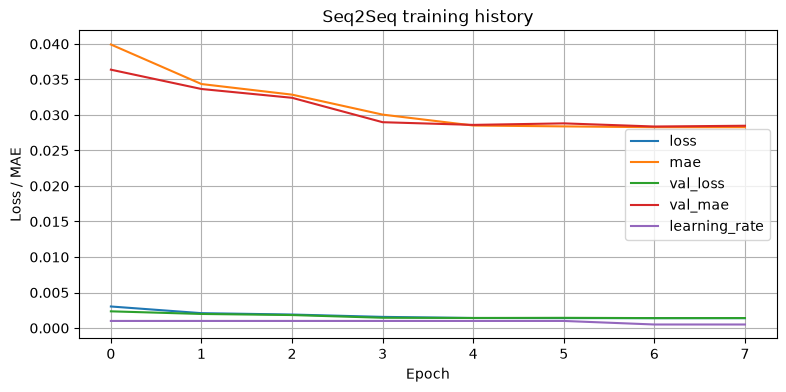

In [6]:
callbacks = [
    EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
]

history = seq2seq_model.fit(
    X_seq, y_seq,
    validation_split=0.1,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    callbacks=callbacks,
    verbose=1
)

pd.DataFrame(history.history).plot(figsize=(9, 4), title="Seq2Seq training history")
plt.xlabel("Epoch")
plt.ylabel("Loss / MAE")
plt.grid(True)
plt.show()

## 7. Train a Day 9-style single-step LSTM baseline

To make the comparison reproducible, this notebook trains a one-step LSTM using the same series, global scaling, look-back length, and training-only time range. At evaluation time, its one-step predictions are fed back recursively to create a 14-day forecast, matching the multi-horizon task.

In [7]:
def build_single_step_lstm(look_back=LOOK_BACK):
    inputs = Input(shape=(look_back, 1))
    x = LSTM(32)(inputs)
    x = Dropout(0.2)(x)
    outputs = Dense(1)(x)
    model = Model(inputs, outputs, name="day09_single_step_lstm")
    model.compile(
        optimizer="adam",
        loss="mse",
        metrics=[tf.keras.metrics.MeanAbsoluteError(name="mae")]
    )
    return model

baseline_model = build_single_step_lstm()
baseline_history = baseline_model.fit(
    X_one, y_one,
    validation_split=0.1,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
    ],
    verbose=1
)

Epoch 1/8
3938/3938 ━━━━━━━━━━━━━━━━━━━━ 110s 26ms/step - loss: 0.0026 - mae: 0.0379 - val_loss: 0.0020 - val_mae: 0.0338 - learning_rate: 0.0010
Epoch 2/8
3938/3938 ━━━━━━━━━━━━━━━━━━━━ 109s 28ms/step - loss: 0.0017 - mae: 0.0319 - val_loss: 0.0014 - val_mae: 0.0288 - learning_rate: 0.0010
Epoch 3/8
3938/3938 ━━━━━━━━━━━━━━━━━━━━ 136s 35ms/step - loss: 0.0016 - mae: 0.0303 - val_loss: 0.0014 - val_mae: 0.0282 - learning_rate: 0.0010
Epoch 4/8
3938/3938 ━━━━━━━━━━━━━━━━━━━━ 118s 30ms/step - loss: 0.0015 - mae: 0.0297 - val_loss: 0.0014 - val_mae: 0.0281 - learning_rate: 0.0010
Epoch 5/8
3938/3938 ━━━━━━━━━━━━━━━━━━━━ 108s 27ms/step - loss: 0.0014 - mae: 0.0292 - val_loss: 0.0013 - val_mae: 0.0274 - learning_rate: 5.0000e-04
Epoch 6/8
3938/3938 ━━━━━━━━━━━━━━━━━━━━ 106s 27ms/step - loss: 0.0014 - mae: 0.0290 - val_loss: 0.0013 - val_mae: 0.0273 - learning_rate: 5.0000e-04
Epoch 7/8
3938/3938 ━━━━━━━━━━━━━━━━━━━━ 112s 28ms/step - loss: 0.0014 - mae: 0.0288 - val_loss: 0.0013 - val_mae: 0

## 8. Evaluate both models on the same 14-day holdout

The Seq2Seq model predicts all 14 steps in one call. The Day 9 baseline predicts one day at a time and recursively appends each prediction to its input window. Metrics are calculated after inverse scaling, in the original sales units.

In [8]:
def recursive_one_step_forecast(model, context_scaled, horizon=HORIZON):
    window = context_scaled.reshape(1, LOOK_BACK, 1).copy()
    predictions = []
    for _ in range(horizon):
        next_value = float(model.predict(window, verbose=0)[0, 0])
        predictions.append(next_value)
        window = np.concatenate(
            [window[:, 1:, :], np.array(next_value, dtype=np.float32).reshape(1, 1, 1)],
            axis=1
        )
    return np.asarray(predictions, dtype=np.float32)

seq_actual_all, seq_pred_all, base_pred_all = [], [], []
per_series_results = []

for key, context, actual in evaluation:
    seq_pred_scaled = seq2seq_model.predict(context[None, ...], verbose=0)[0, :, 0]
    seq_pred = inverse_scale(seq_pred_scaled)
    base_pred_scaled = recursive_one_step_forecast(baseline_model, context[:, 0])
    base_pred = inverse_scale(base_pred_scaled)

    seq_actual_all.extend(actual.tolist())
    seq_pred_all.extend(seq_pred.tolist())
    base_pred_all.extend(base_pred.tolist())

    per_series_results.append({
        "series": str(key),
        "seq2seq_mae": float(np.mean(np.abs(actual - seq_pred))),
        "day09_recursive_mae": float(np.mean(np.abs(actual - base_pred))),
    })

def regression_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=np.float64)
    predicted = np.asarray(predicted, dtype=np.float64)
    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))
    nonzero = np.abs(actual) > 1e-8
    mape = np.mean(np.abs((actual[nonzero] - predicted[nonzero]) / actual[nonzero])) * 100 if nonzero.any() else np.nan
    return {"MAE": mae, "RMSE": rmse, "MAPE_percent_nonzero": mape}

seq_metrics = regression_metrics(seq_actual_all, seq_pred_all)
baseline_metrics = regression_metrics(seq_actual_all, base_pred_all)

comparison = pd.DataFrame([
    {"model": "Day 9 single-step LSTM (recursive)", **baseline_metrics},
    {"model": "Day 10 Seq2Seq + Attention (14-step)", **seq_metrics},
])
comparison

,model,MAE,RMSE,MAPE_percent_nonzero
0,Day 9 single-step LSTM (recursive),14.654056,17.012516,40.152117
1,Day 10 Seq2Seq + Attention (14-step),16.701402,21.859869,46.588403


## 9. Inspect performance by forecast horizon

A multi-horizon model may perform well on near-term days but degrade further into the future. This table reports MAE separately for each of the 14 forecast days.

In [10]:
actual_matrix, seq_matrix, base_matrix = [], [], []
for key, context, actual in evaluation:
    seq_scaled = seq2seq_model.predict(context[None, ...], verbose=0)[0, :, 0]
    seq_matrix.append(inverse_scale(seq_scaled))
    base_scaled = recursive_one_step_forecast(baseline_model, context[:, 0])
    base_matrix.append(inverse_scale(base_scaled))
    actual_matrix.append(actual)

actual_matrix = np.asarray(actual_matrix)
seq_matrix = np.asarray(seq_matrix)
base_matrix = np.asarray(base_matrix)

horizon_report = pd.DataFrame({
    "day_ahead": np.arange(1, HORIZON + 1),
    "seq2seq_attention_mae": np.mean(np.abs(actual_matrix - seq_matrix), axis=0),
    "day09_recursive_mae": np.mean(np.abs(actual_matrix - base_matrix), axis=0),
})
horizon_report

,day_ahead,seq2seq_attention_mae,day09_recursive_mae
0,1,11.513741,16.761072
1,2,11.143970,15.884732
2,3,32.955799,13.292353
3,4,30.930117,13.944489
4,5,7.830038,14.929195
5,6,12.545271,14.236870
6,7,10.020988,14.504847
7,8,11.193429,16.101067
8,9,11.699831,16.148083
9,10,32.731697,13.127667


## 10. Visualize attention weights

The attention matrix has one row per decoder forecast step and one column per historical input day. Larger weights indicate which encoder time steps the decoder attended to more strongly for that forecast step. Attention is an explanatory diagnostic, not proof of causal influence.

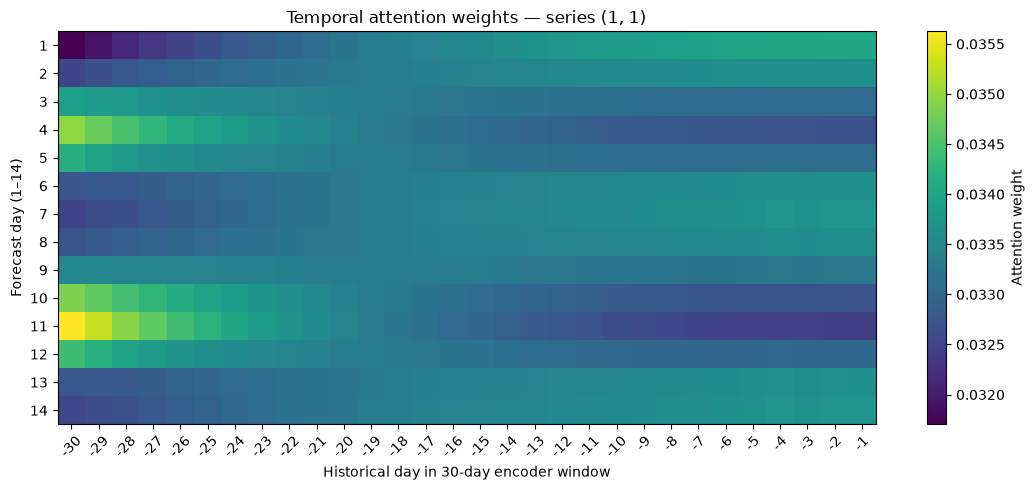

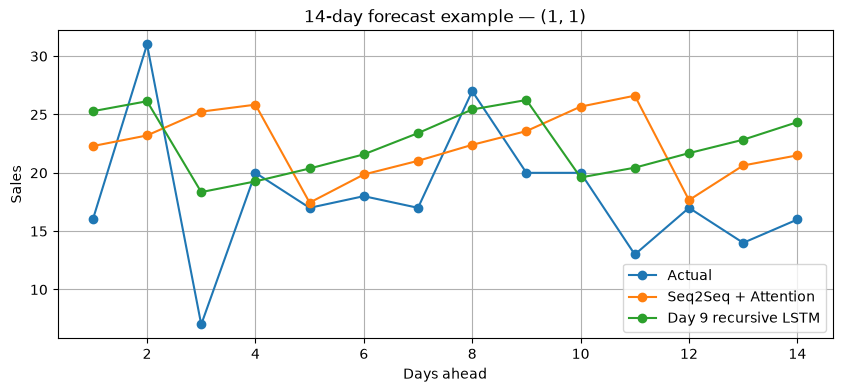

In [11]:
# Visualize one representative evaluation series.
if len(evaluation) > 0:
    sample_key, sample_context, sample_actual = evaluation[0]
    weights = attention_model.predict(sample_context[None, ...], verbose=0)[0]

    plt.figure(figsize=(11, 5))
    plt.imshow(weights, aspect="auto", cmap="viridis")
    plt.colorbar(label="Attention weight")
    plt.xlabel("Historical day in 30-day encoder window")
    plt.ylabel("Forecast day (1–14)")
    plt.title(f"Temporal attention weights — series {sample_key}")
    plt.xticks(range(LOOK_BACK), range(-LOOK_BACK, 0), rotation=45)
    plt.yticks(range(HORIZON), range(1, HORIZON + 1))
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10, 4))
    plt.plot(range(1, HORIZON + 1), sample_actual, marker="o", label="Actual")
    plt.plot(range(1, HORIZON + 1), inverse_scale(
        seq2seq_model.predict(sample_context[None, ...], verbose=0)[0, :, 0]
    ), marker="o", label="Seq2Seq + Attention")
    plt.plot(range(1, HORIZON + 1), inverse_scale(
        recursive_one_step_forecast(baseline_model, sample_context[:, 0])
    ), marker="o", label="Day 9 recursive LSTM")
    plt.title(f"14-day forecast example — {sample_key}")
    plt.xlabel("Days ahead")
    plt.ylabel("Sales")
    plt.legend()
    plt.grid(True)
    plt.show()

## 11. Save model, metrics and experiment artifacts

The model is saved in the same `models/` area used by the Day 9 increment. The comparison and horizon-level metrics are saved under `data/reports/`.

In [12]:
seq_model_path = MODEL_DIR / "demand_seq2seq_attention.keras"
baseline_model_path = MODEL_DIR / "demand_lstm_day09_baseline.keras"

seq2seq_model.save(seq_model_path)
baseline_model.save(baseline_model_path)

comparison_path = REPORT_DIR / "day10_model_comparison.csv"
horizon_path = REPORT_DIR / "day10_horizon_metrics.csv"
series_path = REPORT_DIR / "day10_per_series_metrics.csv"

comparison.to_csv(comparison_path, index=False)
horizon_report.to_csv(horizon_path, index=False)
pd.DataFrame(per_series_results).to_csv(series_path, index=False)

print("Saved:", seq_model_path)
print("Saved:", baseline_model_path)
print("Saved:", comparison_path)
print("Saved:", horizon_path)
print("Saved:", series_path)

Saved: ..\models\demand_seq2seq_attention.keras
Saved: ..\models\demand_lstm_day09_baseline.keras
Saved: ..\data\reports\day10_model_comparison.csv
Saved: ..\data\reports\day10_horizon_metrics.csv
Saved: ..\data\reports\day10_per_series_metrics.csv


## 12. Generate Kaggle test forecasts in 14-day blocks

The Kaggle Store Item Demand test set contains future dates for each store/item. The model emits 14 values per call; predictions are appended to the history and the next block is forecast recursively. The final partial block is trimmed to the exact number of test rows.

This is a multi-week forecasting upgrade over the Day 9 single-step approach.

In [ ]:
def forecast_series_in_blocks(model, history_values, n_steps, horizon=HORIZON):
    history_scaled = list(scale_values(history_values))
    forecasts_scaled = []

    while len(forecasts_scaled) < n_steps:
        context = np.asarray(history_scaled[-LOOK_BACK:], dtype=np.float32)
        if len(context) < LOOK_BACK:
            context = np.pad(context, (LOOK_BACK - len(context), 0), mode="constant")
        block = model.predict(context.reshape(1, LOOK_BACK, 1), verbose=0)[0, :, 0]
        remaining = n_steps - len(forecasts_scaled)
        block = block[:min(horizon, remaining)]
        forecasts_scaled.extend(block.tolist())
        history_scaled.extend(block.tolist())

    forecasts = inverse_scale(np.asarray(forecasts_scaled))
    return np.maximum(forecasts, 0)

submission_parts = []
for key, test_group in test.groupby(GROUP_COLS):
    test_group = test_group.sort_values("date").copy()
    key_tuple = key if isinstance(key, tuple) else (key,)
    history = series_data.get(key_tuple)

    if history is None:
        # Fall back to the available raw training history for this key.
        mask = np.ones(len(train), dtype=bool)
        for col, value in zip(GROUP_COLS, key_tuple):
            mask &= train[col].to_numpy() == value
        group_history = train.loc[mask].sort_values("date")
        history_values = group_history["target"].to_numpy(dtype=np.float32)
    else:
        history_values = history.to_numpy(dtype=np.float32)

    if len(history_values) == 0:
        test_group["forecast"] = 0.0
    else:
        test_group["forecast"] = forecast_series_in_blocks(
            seq2seq_model, history_values, len(test_group), HORIZON
        )
    submission_parts.append(test_group)

submission = pd.concat(submission_parts).sort_index()
if "id" in submission.columns:
    submission_output = submission[["id", "forecast"]].rename(columns={"forecast": "sales"})
else:
    submission_output = submission[["forecast"]].rename(columns={"forecast": "Sales"})

submission_path = Path("../submission_seq2seq_attention.csv")
submission_output.to_csv(submission_path, index=False)
print("Submission saved:", submission_path)
submission_output.head()

## 13. Final experiment summary

Run this cell after the notebook completes. Copy the actual metric values into the Day 10 README. Do not assume attention must beat the Day 9 model: report the measured result honestly and investigate horizon-specific errors.

In [14]:
print("DATASET:", DATASET_TYPE)
print("LOOK_BACK:", LOOK_BACK, "| HORIZON:", HORIZON, "| HOLDOUT_DAYS:", HOLDOUT_DAYS)
print("\nOverall comparison:")
display(comparison)
print("\nHorizon-wise MAE:")
display(horizon_report)
print("\nArtifacts:")
for path in [seq_model_path, baseline_model_path, comparison_path, horizon_path, series_path, submission_path]:
    print(path, "exists =", path.exists())

DATASET: store_item_demand
LOOK_BACK: 30 | HORIZON: 14 | HOLDOUT_DAYS: 30

Overall comparison:


,model,MAE,RMSE,MAPE_percent_nonzero
0,Day 9 single-step LSTM (recursive),14.654056,17.012516,40.152117
1,Day 10 Seq2Seq + Attention (14-step),16.701402,21.859869,46.588403



Horizon-wise MAE:


,day_ahead,seq2seq_attention_mae,day09_recursive_mae
0,1,11.513741,16.761072
1,2,11.143970,15.884732
2,3,32.955799,13.292353
3,4,30.930117,13.944489
4,5,7.830038,14.929195
5,6,12.545271,14.236870
6,7,10.020988,14.504847
7,8,11.193429,16.101067
8,9,11.699831,16.148083
9,10,32.731697,13.127667



Artifacts:
..\models\demand_seq2seq_attention.keras exists = True
..\models\demand_lstm_day09_baseline.keras exists = True
..\data\reports\day10_model_comparison.csv exists = True
..\data\reports\day10_horizon_metrics.csv exists = True
..\data\reports\day10_per_series_metrics.csv exists = True
..\submission_seq2seq_attention.csv exists = True


## 14. Day 10 completion checklist

- [ ] Built 30-day encoder windows and 14-day decoder targets.
- [ ] Trained an LSTM encoder–decoder with temporal attention.
- [ ] Trained a Day 9-style single-step LSTM baseline and evaluated it recursively.
- [ ] Compared MAE, RMSE and non-zero MAPE over the same held-out 14-day horizon.
- [ ] Reviewed horizon-wise errors and visualized attention weights.
- [ ] Saved the Keras models and CSV experiment reports.
- [ ] Generated a multi-week Kaggle test submission.
- [ ] Updated the RetailMind demand module to use the Seq2Seq model for block forecasts.

**Limitations:** the notebook uses sales history only, so it does not yet incorporate calendar, promotion, holiday, price, or store metadata. Attention weights are descriptive diagnostics, not causal explanations. The evaluation uses the first 14 days of a 30-day holdout so every series has the same forecast horizon.